# Mechanistic vs learned: two models on the same teams

`mechanistic_model.ipynb` asked whether the CV32E40X manual's cycle table predicts
team latency. This notebook puts that model side by side with the **learned** one —
the Lasso regression in `analysis/regression.py` — on identical data, identical
splits, and identical metrics.

| | Mechanistic | Learned |
|---|---|---|
| Source of costs | CV32E40X user manual | fitted from these measurements |
| Free parameters | **0** | one weight per surviving feature |
| Features | per-operation counts | per-operation counts **+ distance-1 RAW hazards** |
| Entry point | `Disassembler.estimate_block_latency` | `Regressor.train` -> `RegressionModel` |

**Fairness rules, enforced below.** The learned model is only ever scored on teams it
did not train on. The mechanistic model has no training fold, so it is scored on
*that same held-out fold* rather than on everything — otherwise the comparison
flatters it. Everything is reported three ways — straight-line, branchy, and the two
pooled — because section 4 of the first notebook showed the two regimes behave
nothing alike, and the pooled row is what a single model actually delivers.

**The interesting question is not which wins.** The learned model has free
parameters and must win. It is whether the learned weights *rediscover the manual's
cycle counts* (section 4) — if they do, the mechanistic model is validated and the
regression is merely re-measuring the hardware; if they don't, the regression is
absorbing something the manual does not describe.

> Needs a Jupyter kernel: `sudo apt install python3-ipykernel`.

In [16]:
# --- Configuration -----------------------------------------------------------
DB_PATH   = "db_fixedpt_iset32_noipa" #"db_tpg_float_iset32"
UARCH     = "cv32e40x_im1_zba_zbb" #"cv32e40px_fpu" 
TEST_SIZE = 0.20      # must match what Regressor.train is called with
SEED      = 0         # must match its random_state

import sys, os
from dataclasses import dataclass

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

ROOT = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(ROOT, "classes")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
os.chdir(ROOT)

from classes.database import Database
from classes.features import FeatureVector
from analysis.disassembler import Disassembler
from analysis.analyzer import FeaturesAnalyzer
from analysis.regression import Regressor

db = Database.load(DB_PATH)
print(f"{len(db.tpgs)} TPGs | uarch {UARCH}")

[Database] Loaded from db_fixedpt_iset32_noipa  (161 TPGs, 2 ISAs, 2 uarchs)
161 TPGs | uarch cv32e40x_im1_zba_zbb


In [17]:
# --- Style + palette (an entity keeps its colour in every figure) ------------
C_MECH  = "#2a78d6"   # slot 1, blue   -- mechanistic (doc table)
C_LEARN = "#eb6834"   # slot 2, orange -- learned (Lasso)
INK, MUTED = "#3d3d3a", "#8a8a80"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": "#e6e6e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 11, "axes.titlelocation": "left", "axes.titleweight": "semibold",
    "font.size": 9, "legend.frameon": False,
})

# Same definition as notebook 1: any control-flow instruction makes a team branchy.
CONTROL_FLOW = {
    "beq", "bne", "blt", "bge", "bltu", "bgeu",
    "beqz", "bnez", "blez", "bgez", "bltz", "bgtz", "bgt", "ble", "bgtu", "bleu",
    "jal", "jalr", "j", "jr", "ret", "call", "tail",
}

def metrics(y, p):
    """MAE, RMSE, MAPE and R2 for one set of predictions.

    MAPE is scale-free, so it is the one metric that compares straight-line
    teams against branchy ones on equal terms -- the two populations sit at
    very different latencies, so the same MAE means something very different
    in each.

    Watch for MAE and MAPE disagreeing: that means a model is winning on the
    large-latency teams while getting the small ones proportionally wrong.
    """
    y, p = np.asarray(y, float), np.asarray(p, float)
    err = y - p
    return dict(mae=float(np.abs(err).mean()),
                rmse=float(np.sqrt((err ** 2).mean())),
                mape=float((np.abs(err) / np.maximum(np.abs(y), 1e-9)).mean() * 100),
                r2=float(1 - (err ** 2).sum() / ((y - y.mean()) ** 2).sum()))

def fmt(m):
    return (f"MAE={m['mae']:7.2f}  RMSE={m['rmse']:7.2f}  "
            f"MAPE={m['mape']:6.1f}%  R2={m['r2']:8.4f}")
print("ready")

ready


## 1. Dataset

One row per measured team: the feature vector the learned model consumes, the
mechanistic estimate, the measurement, and the straight-line / branchy label.

In [18]:
@dataclass
class Row:
    fv: FeatureVector; est: float; meas: float; n: int; branchy: bool

rows = []
for tpg, tid, ct, m in db.get_measurements_for_uarch(UARCH):
    ins = ct.instructions or []
    if not ins:
        continue
    rows.append(Row(
        fv=FeaturesAnalyzer.analyze_instructions(ins),
        est=Disassembler.estimate_block_latency(ins),
        meas=m.latency, n=len(ins),
        branchy=any(i.mnemonic.lower() in CONTROL_FLOW for i in ins),
    ))

meas = np.array([r.meas for r in rows], float)
SL   = np.array([not r.branchy for r in rows])

# GROUPS  = the two regimes; these are the populations a model is tested on.
# FIT_SETS = what a model is trained on. "straight + branchy" is one pooled
#   model over everything -- the same thing `main.py train` builds today, and
#   the row to look at if you want a single model rather than two specialists.
GROUPS   = {"straight-line": SL, "branchy": ~SL}
FIT_SETS = {**GROUPS, "straight + branchy": np.ones(len(rows), bool)}
SHORT    = {"straight-line": "straight", "branchy": "branchy",
            "straight + branchy": "pooled"}

for name, mask in FIT_SETS.items():
    print(f"{name:<20} {mask.sum():>5} teams   measured mean {meas[mask].mean():7.1f}  "
          f"median {np.median(meas[mask]):6.1f}  max {meas[mask].max():6.1f} cycles")

straight-line         1996 teams   measured mean    30.4  median   26.0  max  179.0 cycles
branchy               1290 teams   measured mean   144.2  median   86.0  max 1116.0 cycles
straight + branchy    3286 teams   measured mean    75.1  median   34.0  max 1116.0 cycles


## 2. Training, with the held-out fold recovered

`Regressor.train` performs its own 80/20 split internally and does not return which
rows landed in the test fold. But `sklearn.train_test_split` is deterministic given
`(n_samples, test_size, random_state)` — the permutation does not depend on the
array contents, only on those three — so calling it on an index array with the same
three values reproduces that partition exactly.

The cell below checks that the recovery worked: the test-fold MAE recomputed through
`RegressionModel.predict` must equal the MAE `Regressor.train` reported internally.
That single check validates two things at once — the split recovery, and that
`predict()` reproduces the fitted model when applied to raw feature vectors.

**If it prints FAIL, stop and fix that first**; every comparison below depends on it.

In [19]:
def fit_group(mask, label):
    idx = np.flatnonzero(mask)
    fvs = [rows[i].fv for i in idx]
    ys  = [rows[i].meas for i in idx]

    model = Regressor.train(fvs, ys, test_size=TEST_SIZE, random_state=SEED)

    # Same n, same test_size, same seed -> same partition as inside train().
    tr_local, te_local = train_test_split(
        np.arange(len(idx)), test_size=TEST_SIZE, random_state=SEED)
    train_idx, test_idx = idx[tr_local], idx[te_local]

    recomputed = metrics([rows[i].meas for i in test_idx],
                         [model.predict(rows[i].fv) for i in test_idx])
    reported = model.test_metrics
    delta = abs(recomputed["mae"] - reported.mae)
    ok = delta < 1e-6
    print(f"{label}: split recovery + predict() check {'PASS' if ok else 'FAIL'}  "
          f"(recomputed MAE {recomputed['mae']:.6f} vs reported {reported.mae:.6f}, "
          f"delta {delta:.2e})")
    if not ok:
        print("  !! Everything below would then be comparing a prediction path that")
        print("     does not match the fitted model. Fix this before reading any")
        print("     number in this notebook.")
    return model, train_idx, test_idx

models, splits = {}, {}
for name, mask in FIT_SETS.items():
    models[name], tr, te = fit_group(mask, name)
    splits[name] = (tr, te)
    nz = sum(1 for w in models[name].weights.values() if w != 0)
    print(f"  -> {len(tr)} train / {len(te)} test, alpha={models[name].alpha:.4f}, "
          f"{nz} non-zero weights")
    print()

alpha_max (grid top): 17.16863449161621
alpha_min (grid bottom): 0.01716863449161621
n_alphas in grid: 100
chosen alpha: 0.018409364012035925
straight-line: split recovery + predict() check PASS  (recomputed MAE 0.745463 vs reported 0.745463, delta 1.11e-16)
  -> 1596 train / 400 test, alpha=0.0184, 24 non-zero weights

alpha_max (grid top): 97.41406610643386
alpha_min (grid bottom): 0.09741406610643387
n_alphas in grid: 100
chosen alpha: 0.13808192181151374
branchy: split recovery + predict() check PASS  (recomputed MAE 37.448402 vs reported 37.448402, delta 0.00e+00)
  -> 1032 train / 258 test, alpha=0.1381, 26 non-zero weights

alpha_max (grid top): 72.94733226866137
alpha_min (grid bottom): 0.07294733226866137
n_alphas in grid: 100
chosen alpha: 0.1937545180373441
straight + branchy: split recovery + predict() check PASS  (recomputed MAE 18.733622 vs reported 18.733622, delta 0.00e+00)
  -> 2628 train / 658 test, alpha=0.1938, 29 non-zero weights



## 3. Head to head, on the held-out fold only

Three fit sets: the two specialists, and one **pooled** model trained on everything
— which is what `main.py train` builds today, and the honest answer to "how good is
the model, overall".

Four metrics, because they answer different questions:

| | what it tells you |
|---|---|
| **MAE** | typical error in cycles, in this population's own units |
| **RMSE** | same, but a few large misses dominate it — compare to MAE to detect outliers |
| **MAPE** | error relative to the team's own latency — **the only one comparable across the three rows** |
| **R2** | share of the variance explained; goes negative when a model is worse than predicting the mean |

MAE and RMSE cannot be compared between straight-line teams (measured mean ~32
cycles) and branchy ones (~163): 10 cycles of error means something completely
different in each. MAPE is the cross-row column.

In [20]:
results = {}
for name, mask in FIT_SETS.items():
    tr, te = splits[name]
    y = np.array([rows[i].meas for i in te])
    p_mech  = np.array([rows[i].est for i in te])
    p_learn = np.array([models[name].predict(rows[i].fv) for i in te])
    results[name] = dict(
        y=y, mech=p_mech, learn=p_learn,
        m_mech=metrics(y, p_mech), m_learn=metrics(y, p_learn),
        # learned model on its own training fold, to expose overfitting
        m_learn_train=metrics([rows[i].meas for i in tr],
                              [models[name].predict(rows[i].fv) for i in tr]))

for name in FIT_SETS:
    r = results[name]
    print(f"{name.upper()}  ({len(r['y'])} held-out teams, "
          f"measured mean {r['y'].mean():.1f} cycles)")
    print(f"  mechanistic (0 params)   {fmt(r['m_mech'])}")
    print(f"  learned      test        {fmt(r['m_learn'])}")
    print(f"  learned      train       {fmt(r['m_learn_train'])}")
    print(f"  -> learned cuts MAE by {r['m_mech']['mae'] / r['m_learn']['mae']:.1f}x, "
          f"MAPE by {r['m_mech']['mape'] / r['m_learn']['mape']:.1f}x")
    print()

# Compact side-by-side view of the three fit sets.
print(f"{'fit set':<20}{'model':<13}{'MAE':>9}{'RMSE':>9}{'MAPE':>9}{'R2':>10}")
print("-" * 70)
for name in FIT_SETS:
    r = results[name]
    for lbl, key in (("mechanistic", "m_mech"), ("learned", "m_learn")):
        m = r[key]
        print(f"{name if lbl == 'mechanistic' else '':<20}{lbl:<13}"
              f"{m['mae']:>9.2f}{m['rmse']:>9.2f}{m['mape']:>8.1f}%{m['r2']:>10.4f}")
print("-" * 70)
sl_mean = results["straight-line"]["y"].mean()
br_mean = results["branchy"]["y"].mean()
print(f"MAE cannot be compared down this table: straight-line teams average "
      f"{sl_mean:.0f} cycles")
print(f"and branchy ones {br_mean:.0f}, so the same cycle error means "
      f"{br_mean / sl_mean:.0f}x less in one than the other.")
print("MAPE is the column that reads across rows. Where MAE and MAPE disagree, the")
print("model is winning on the big teams and losing proportionally on the small ones.")

STRAIGHT-LINE  (400 held-out teams, measured mean 30.7 cycles)
  mechanistic (0 params)   MAE=  10.87  RMSE=  11.40  MAPE=  41.6%  R2=  0.6278
  learned      test        MAE=   0.75  RMSE=   1.59  MAPE=   4.5%  R2=  0.9928
  learned      train       MAE=   0.62  RMSE=   1.04  MAPE=   2.9%  R2=  0.9968
  -> learned cuts MAE by 14.6x, MAPE by 9.1x

BRANCHY  (258 held-out teams, measured mean 153.7 cycles)
  mechanistic (0 params)   MAE= 128.22  RMSE= 196.91  MAPE=  66.9%  R2= -0.6901
  learned      test        MAE=  37.45  RMSE=  57.77  MAPE=  34.8%  R2=  0.8546
  learned      train       MAE=  40.80  RMSE=  64.97  MAPE=  46.5%  R2=  0.8140
  -> learned cuts MAE by 3.4x, MAPE by 1.9x

STRAIGHT + BRANCHY  (658 held-out teams, measured mean 75.3 cycles)
  mechanistic (0 params)   MAE=  53.51  RMSE= 114.45  MAPE=  51.5%  R2= -0.1818
  learned      test        MAE=  18.73  RMSE=  44.88  MAPE=  23.1%  R2=  0.8183
  learned      train       MAE=  16.53  RMSE=  38.86  MAPE=  23.1%  R2=  0.8794


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


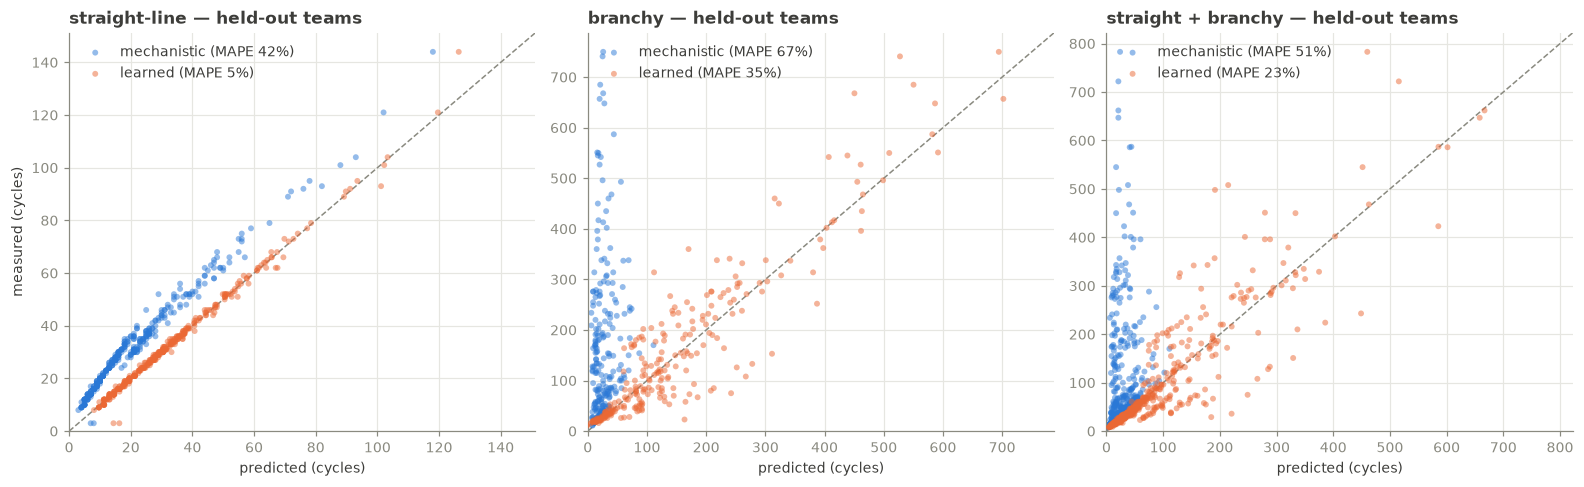

In [21]:
fig, axes = plt.subplots(1, len(FIT_SETS), figsize=(14.5, 4.5))
for k, (ax, name) in enumerate(zip(axes, FIT_SETS)):
    r = results[name]
    lim = max(r["y"].max(), r["mech"].max(), r["learn"].max()) * 1.05
    ax.plot([0, lim], [0, lim], color=MUTED, lw=1, ls="--", zorder=1)
    ax.scatter(r["mech"], r["y"], s=15, color=C_MECH, alpha=0.5, edgecolor="none",
               label=f"mechanistic (MAPE {r['m_mech']['mape']:.0f}%)", zorder=2)
    ax.scatter(r["learn"], r["y"], s=15, color=C_LEARN, alpha=0.5, edgecolor="none",
               label=f"learned (MAPE {r['m_learn']['mape']:.0f}%)", zorder=3)
    ax.set(xlim=(0, lim), ylim=(0, lim), xlabel="predicted (cycles)",
           ylabel="measured (cycles)" if k == 0 else "",
           title=f"{name} — held-out teams")
    ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

**Reading it.** The dashed line is a perfect prediction. Mechanistic points sit
*below* it on straight-line teams — it is a floor, by construction — and scatter to
both sides on branchy teams, where the floor property already failed. Learned points
straddle the line in both panels: a fitted model has no reason to be biased.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


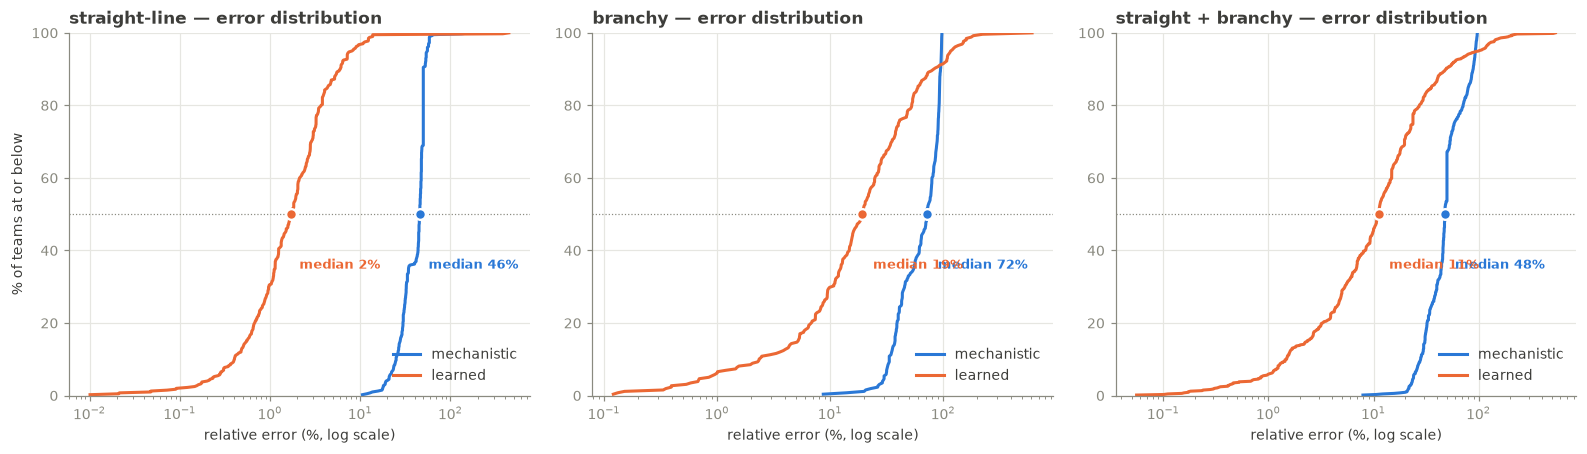

In [22]:
"""Relative error is the fair axis here, because the three fit sets live at very
different latency scales. 100% means the prediction was off by the size of the
measurement itself."""
fig, axes = plt.subplots(1, len(FIT_SETS), figsize=(14.5, 4.2))
for k, (ax, name) in enumerate(zip(axes, FIT_SETS)):
    r = results[name]
    for key, color, lbl in (("mech", C_MECH, "mechanistic"), ("learn", C_LEARN, "learned")):
        # clamped off zero so an exact hit stays visible on the log axis
        pct = np.sort(np.maximum(
            np.abs(r["y"] - r[key]) / np.maximum(np.abs(r["y"]), 1e-9) * 100, 1e-2))
        ax.plot(pct, np.arange(1, len(pct) + 1) / len(pct) * 100,
                color=color, lw=2, label=lbl)
        med = float(np.median(pct))
        ax.plot([med], [50], "o", color=color, ms=7, mec="white", mew=1.5, zorder=5)
        ax.annotate(f"median {med:.0f}%", xy=(med, 50), xytext=(med * 1.25, 50 - 15),
                    color=color, fontsize=8.5, fontweight="semibold")
    ax.axhline(50, color=MUTED, lw=0.8, ls=":")
    ax.set(xscale="log", xlabel="relative error (%, log scale)",
           ylabel="% of teams at or below" if k == 0 else "",
           ylim=(0, 100), title=f"{name} — error distribution")
    ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

### 3b. Putting R2 in perspective against the spread of the fold

R2 is **already** normalised by the spread of the data it is scored on:

$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

The denominator is the test fold's own variance. That makes R2 scale-free, but it
also means **a fold with a huge spread gives away a high R2 cheaply** — if latencies
run from 20 to 5892 cycles, merely telling big teams from small ones already explains
most of the variance, while every prediction can still be off by 90% in relative
terms. That is exactly the branchy situation, and it is why its R2 (0.62) and its
MAPE (96%) tell opposite stories.

Five diagnostics that put the number back in context:

| | what it adds |
|---|---|
| **CV of the fold** (std / mean) | how much spread the R2 was normalised against |
| **RMSE / std** | the same information as R2 — it *is* sqrt(1 - R2) — restated as "residual as a fraction of the data's own spread", which is harder to over-read |
| **variance concentration** | share of the total sum of squares held by the top 1 / 5 / 10% of teams; if a handful dominate, R2 only measures whether those few were placed roughly right |
| **R2 on log10(latency)** | the same fit judged on *relative* error. A large drop from the linear R2 means the model has the order of magnitude right and little else |
| **baselines** | R2 = 0 is "predict the mean" by construction — a floor, not a real competitor. The instruction-count line is the baseline that actually has to be beaten |

In [23]:
def dispersion(y):
    y = np.asarray(y, float)
    q1, med, q3 = np.percentile(y, [25, 50, 75])
    return dict(mean=y.mean(), std=y.std(ddof=1), cv=y.std(ddof=1) / y.mean() * 100,
                median=med, iqr=q3 - q1, mx=y.max(), mx_over_med=y.max() / med)

def ss_concentration(y, frac):
    """Share of the fold's total sum of squares held by its top `frac` of teams."""
    y = np.asarray(y, float)
    ss = (y - y.mean()) ** 2
    k = max(1, int(round(len(y) * frac)))
    return np.sort(ss)[::-1][:k].sum() / ss.sum() * 100

def r2_log(y, p):
    """R2 computed on log10(latency): weights every team by relative error."""
    y = np.log10(np.maximum(np.asarray(y, float), 1e-9))
    p = np.log10(np.maximum(np.asarray(p, float), 1e-9))   # predictions can go <= 0
    return float(1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum())

for name in FIT_SETS:
    tr, te = splits[name]
    r = results[name]
    y, y_tr = r["y"], np.array([rows[i].meas for i in tr])
    d = dispersion(y)

    print(f"{name.upper()}  ({len(y)} held-out teams)")
    print(f"  spread of the fold      mean {d['mean']:.1f}  std {d['std']:.1f}  "
          f"CV {d['cv']:.0f}%   median {d['median']:.1f}  IQR {d['iqr']:.1f}  "
          f"max {d['mx']:.0f} ({d['mx_over_med']:.1f}x median)")
    print(f"  variance concentration  top 1% of teams hold {ss_concentration(y, 0.01):.0f}% "
          f"of the fold's total SS, top 5% hold {ss_concentration(y, 0.05):.0f}%, "
          f"top 10% hold {ss_concentration(y, 0.10):.0f}%")

    # Trivial baselines, all fitted on the training fold only.
    n_tr = np.array([rows[i].n for i in tr], float)
    n_te = np.array([rows[i].n for i in te], float)
    beta = np.linalg.lstsq(np.vstack([n_tr, np.ones_like(n_tr)]).T, y_tr, rcond=None)[0]
    base = {
        "predict train mean":   np.full(len(y), y_tr.mean()),
        "predict train median": np.full(len(y), np.median(y_tr)),
        "predict from instr count": beta[0] * n_te + beta[1],
    }
    print("  baselines               " + "   ".join(
        f"{k}: MAE {metrics(y, v)['mae']:.1f} / R2 {metrics(y, v)['r2']:.3f}"
        for k, v in base.items()))

    print(f"  {'model':<13}{'R2':>9}{'RMSE/std':>10}{'R2 on log':>11}{'MAPE':>8}")
    for lbl, key in (("mechanistic", "mech"), ("learned", "learn")):
        m = r["m_" + ("mech" if key == "mech" else "learn")]
        print(f"  {lbl:<13}{m['r2']:>9.4f}{m['rmse'] / d['std']:>10.2f}"
              f"{r2_log(y, r[key]):>11.4f}{m['mape']:>7.1f}%")
    print()

print("How to read this")
print("  CV of the fold  -- the spread R2 is normalised against. A high-CV fold makes")
print("                     a high R2 cheap: just separating big teams from small ones")
print("                     already explains most of the variance.")
print("  RMSE/std        -- identical information to R2 (it is sqrt(1-R2)), but stated")
print("                     as 'residual as a fraction of the data's own spread'.")
print("  variance concn  -- if a handful of teams hold most of the SS, R2 is really")
print("                     measuring whether those few were placed roughly right.")
print("  R2 on log       -- the same fit judged on relative error. A big gap below the")
print("                     linear R2 means the model only has the scale right.")
print("  baselines       -- R2=0 is 'predict the mean' by construction. The instruction")
print("                     -count line is the baseline that actually has to be beaten.")

STRAIGHT-LINE  (400 held-out teams)
  spread of the fold      mean 30.7  std 18.7  CV 61%   median 27.0  IQR 20.2  max 144 (5.3x median)
  variance concentration  top 1% of teams hold 22% of the fold's total SS, top 5% hold 49%, top 10% hold 62%
  baselines               predict train mean: MAE 13.4 / R2 -0.000   predict train median: MAE 13.3 / R2 -0.092   predict from instr count: MAE 1.3 / R2 0.989
  model               R2  RMSE/std  R2 on log    MAPE
  mechanistic     0.6278      0.61    -0.0611   41.6%
  learned         0.9928      0.08     0.9536    4.5%

BRANCHY  (258 held-out teams)
  spread of the fold      mean 153.7  std 151.8  CV 99%   median 101.5  IQR 175.8  max 750 (7.4x median)
  variance concentration  top 1% of teams hold 17% of the fold's total SS, top 5% hold 47%, top 10% hold 63%
  baselines               predict train mean: MAE 111.8 / R2 -0.006   predict train median: MAE 108.0 / R2 -0.218   predict from instr count: MAE 112.0 / R2 -0.001
  model               R2

## 4. Does the learned model rediscover the manual?

This is the question that matters. Both sets of weights are in the same units —
**cycles per occurrence** — so they can be read against each other directly.

Two cautions carried over from notebook 1. Lasso with `positive=True` cannot express
a negative cost, and `Regressor.train` drops any feature appearing in fewer than 15
training teams, so rare operations get folded into whatever correlates with them.
And the count and hazard features are collinear, so an individual weight is a
*fitted share of the total*, not an independent measurement of that instruction.

In [24]:
def weight_table(model, label):
    ops = [(k[:-len("_count")], w) for k, w in model.weights.items()
           if k.endswith("_count") and not k.startswith("raw_d") and w != 0.0]
    ops.sort(key=lambda kv: -kv[1])
    print(f"{label}  ({len(ops)} non-zero operation weights)")
    print(f"  {'operation':<22}{'learned':>9}{'doc':>7}{'ratio':>8}")
    print("  " + "-" * 46)
    out = []
    for op, w in ops:
        d = Disassembler.operation_latency(op)
        print(f"  {op:<22}{w:>9.3f}{d:>7}{w / d:>8.2f}")
        out.append((op, w, d))
    haz = {k: w for k, w in model.weights.items() if k.startswith("raw_d") and w != 0}
    print(f"  ...plus {len(haz)} non-zero hazard weights, "
          f"summing to {sum(haz.values()):.2f} cycles")
    print(f"  intercept: {model.bias:+.2f} cycles")
    print()
    return out

WEIGHTS = {name: weight_table(models[name], name.upper() + " MODEL")
           for name in FIT_SETS}

STRAIGHT-LINE MODEL  (12 non-zero operation weights)
  operation               learned    doc   ratio
  ----------------------------------------------
  mulhu                     5.328      4    1.33
  sw                        1.779      1    1.78
  lw                        1.729      1    1.73
  slli                      1.329      1    1.33
  add                       1.226      1    1.23
  srai                      1.179      1    1.18
  sub                       1.126      1    1.13
  neg                       1.036      1    1.04
  max                       1.011      1    1.01
  sh1add                    0.959      1    0.96
  mul                       0.297      1    0.30
  srli                      0.002      1    0.00
  ...plus 12 non-zero hazard weights, summing to 4.53 cycles
  intercept: +2.79 cycles

BRANCHY MODEL  (15 non-zero operation weights)
  operation               learned    doc   ratio
  ----------------------------------------------
  jal_fixedpt_tan_wdiv32  26

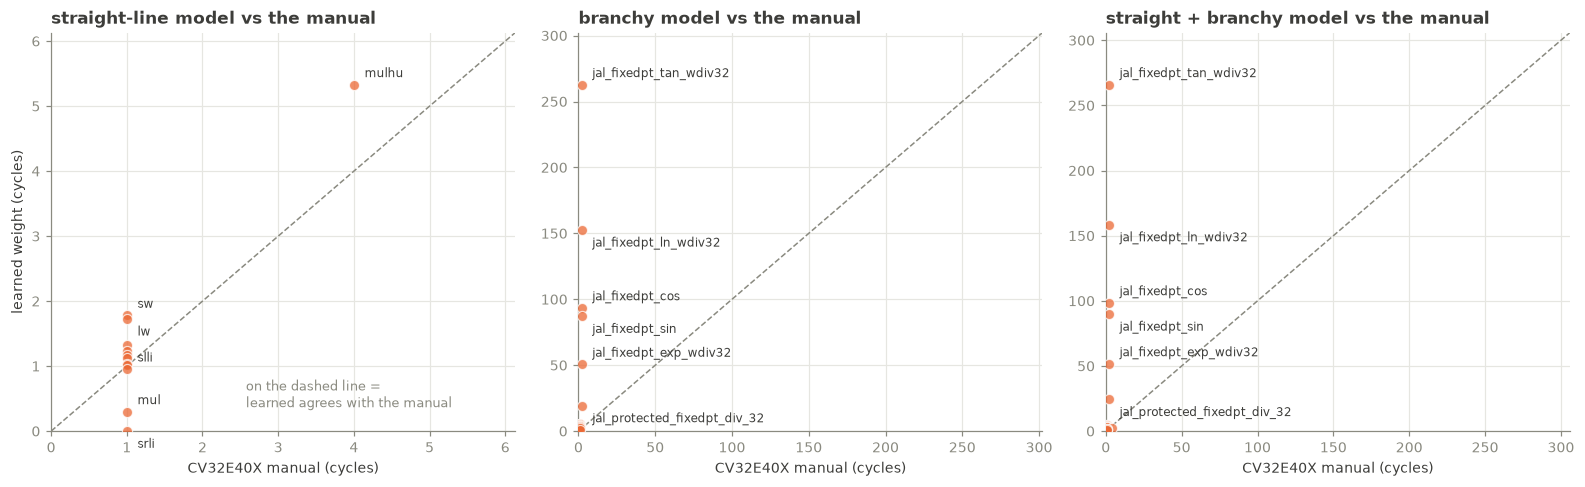

In [25]:
fig, axes = plt.subplots(1, len(FIT_SETS), figsize=(14.5, 4.5))
for k, (ax, name) in enumerate(zip(axes, FIT_SETS)):
    tbl = WEIGHTS[name]
    if not tbl:
        ax.set_title(f"{name} — no non-zero operation weights")
        continue
    doc = np.array([d for _o, _w, d in tbl], float)
    lrn = np.array([w for _o, w, _d in tbl], float)
    hi = max(doc.max(), lrn.max()) * 1.15
    ax.plot([0, hi], [0, hi], color=MUTED, lw=1, ls="--")
    ax.scatter(doc, lrn, s=44, color=C_LEARN, alpha=0.75,
               edgecolor="white", linewidth=0.8, zorder=3)
    # Label the biggest disagreements rather than every point, alternating the
    # offset so labels on near-identical weights do not sit on top of each other.
    for j, i in enumerate(np.argsort(-np.abs(lrn - doc))[:6]):
        dy = 5 if j % 2 == 0 else -11
        ax.annotate(tbl[i][0], xy=(doc[i], lrn[i]), xytext=(7, dy),
                    textcoords="offset points", fontsize=8, color=INK)
    ax.set(xlabel="CV32E40X manual (cycles)", xlim=(0, hi), ylim=(0, hi),
           ylabel="learned weight (cycles)" if k == 0 else "",
           title=f"{name} model vs the manual")
    if k == 0:
        ax.annotate("on the dashed line =\nlearned agrees with the manual",
                    xy=(hi * 0.42, hi * 0.06), fontsize=8.5, color=MUTED)
plt.tight_layout(); plt.show()

In [26]:
# Aggregate agreement: does the learned model price a whole team like the manual?
# Strip the hazard weights and the intercept, leaving the learned model's own
# "cost table" applied to the same counts the manual is applied to.
for name in FIT_SETS:
    model = models[name]
    _tr, te = splits[name]

    def learned_ops_only(fv, model=model):
        return sum(w * fv.get(k, 0.0) for k, w in model.weights.items()
                   if k.endswith("_count") and not k.startswith("raw_d"))

    a = np.array([learned_ops_only(rows[i].fv) for i in te])
    b = np.array([rows[i].est for i in te])
    print(f"{name:<20} learned counts-only vs manual estimate: "
          f"r={np.corrcoef(a, b)[0, 1]:.4f}, "
          f"mean ratio {np.mean(a / np.maximum(b, 1e-9)):.2f}")

straight-line        learned counts-only vs manual estimate: r=0.9908, mean ratio 1.45
branchy              learned counts-only vs manual estimate: r=0.2153, mean ratio 7.47
straight + branchy   learned counts-only vs manual estimate: r=0.3234, mean ratio 3.96


## 5. Does the learned model generalise, or memorise this workload?

Every model against every population — a 3x3 grid. The diagonal is each model on its
own held-out fold; everything off it is a population the model was never fitted for.
The mechanistic model is the control: it has no training fold, so its column cannot
change with the direction of transfer.

Every cell drops the teams in the *model's own training fold*, which is the one rule
that keeps all three models honest:

| model | on its own regime | on the other regime | on straight + branchy |
|---|---|---|---|
| straight-line | its held-out 20% | every branchy team (never seen) | everything bar its own training fold |
| branchy | its held-out 20% | every straight-line team (never seen) | everything bar its own training fold |
| pooled | the part of that regime in its held-out 20% | same | its held-out 20% |

That is why rows involving the pooled set have a smaller `n`: the pooled model
trained on 80% of *both* regimes, so less is left to score it on.

In [27]:
def transfer_rows():
    """Every (model, population) pair, always scored on teams the model never saw.

    One rule covers every case: drop any team in the model's own training fold.
    For a specialist tested on its own regime that leaves exactly that regime's
    held-out fold; tested on the other regime it leaves all of it (disjoint
    training set); for anything involving the pooled set it leaves whatever fell
    outside the relevant 80% -- which is why those rows have a smaller n.
    """
    for src in FIT_SETS:
        src_train = set(splits[src][0].tolist())
        for dst in FIT_SETS:
            idx = np.array([i for i in np.flatnonzero(FIT_SETS[dst])
                            if i not in src_train])
            y  = np.array([rows[i].meas for i in idx])
            pl = np.array([models[src].predict(rows[i].fv) for i in idx])
            pm = np.array([rows[i].est for i in idx])
            yield src, dst, len(idx), metrics(y, pl), metrics(y, pm)

print(f"{'trained on -> tested on':<26}{'n':>6}"
      f"{'learned MAE':>13}{'mech MAE':>11}{'learned MAPE':>14}{'mech MAPE':>12}"
      f"{'learned R2':>12}")
print("-" * 94)
last = None
for src, dst, n, ml, mm in transfer_rows():
    if last is not None and src != last:
        print()
    last = src
    own = "  *" if src == dst else ""
    print(f"{SHORT[src] + ' -> ' + SHORT[dst] + own:<26}{n:>6}"
          f"{ml['mae']:>13.2f}{mm['mae']:>11.2f}"
          f"{ml['mape']:>13.1f}%{mm['mape']:>11.1f}%{ml['r2']:>12.4f}")
print("\n* = the model's own held-out fold (the diagonal). Everything off the diagonal")
print("  is a population the model was not fitted for.")

trained on -> tested on        n  learned MAE   mech MAE  learned MAPE   mech MAPE  learned R2
----------------------------------------------------------------------------------------------
straight -> straight  *      400         0.75      10.87          4.5%       41.6%      0.9928
straight -> branchy         1290       112.44     119.32         57.4%       66.8%     -0.5136
straight -> pooled          1690        86.00      93.65         44.9%       60.8%     -0.3291

branchy -> straight         1996         7.87      10.96         31.0%       41.7%      0.6208
branchy -> branchy  *        258        37.45     128.22         34.8%       66.9%      0.8546
branchy -> pooled           2254        11.26      24.39         31.4%       44.6%      0.8892

pooled -> straight           388         2.96      10.81         11.8%       41.5%      0.9412
pooled -> branchy            270        41.40     114.86         39.2%       65.9%      0.7476
pooled -> pooled  *          658        18.73   

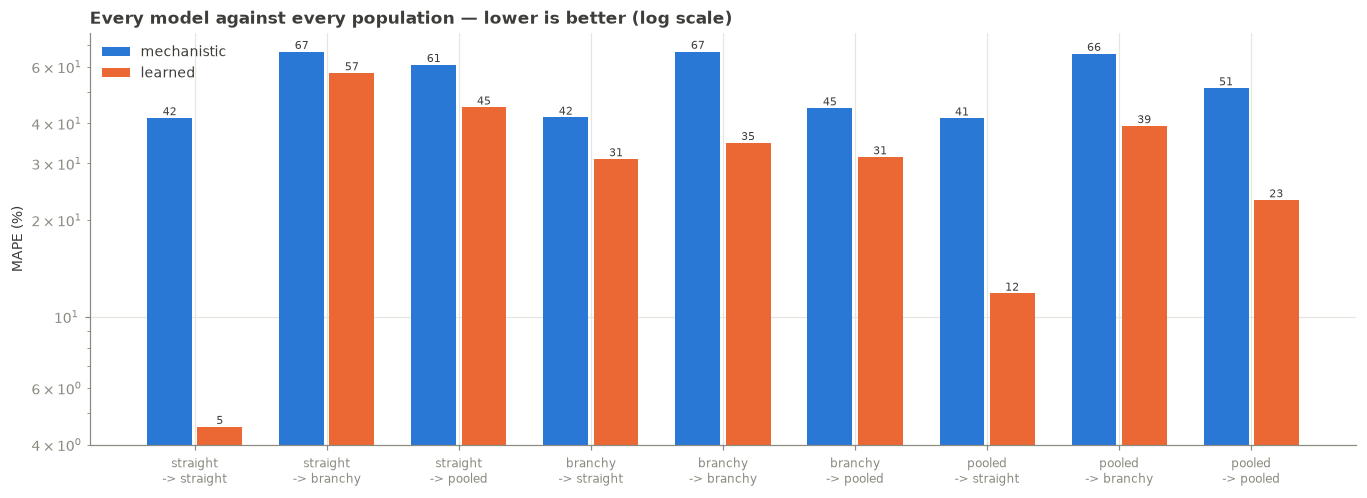

In [28]:
# MAPE, not MAE, so bars from different populations sit on one scale.
fig, ax = plt.subplots(figsize=(12.5, 4.6))
labels, learn_v, mech_v, diag = [], [], [], []
for src, dst, n, ml, mm in transfer_rows():
    labels.append(f"{SHORT[src]}\n-> {SHORT[dst]}")
    learn_v.append(ml["mape"])
    mech_v.append(mm["mape"])
    diag.append(src == dst)

x = np.arange(len(labels)); w = 0.38
ax.bar(x - w / 2, mech_v, w - 0.04, color=C_MECH, label="mechanistic")
ax.bar(x + w / 2, learn_v, w - 0.04, color=C_LEARN, label="learned")
for xi, v in zip(x - w / 2, mech_v):
    ax.annotate(f"{v:.0f}", (xi, v), ha="center", va="bottom", fontsize=7.5, color=INK)
for xi, v in zip(x + w / 2, learn_v):
    ax.annotate(f"{v:.0f}", (xi, v), ha="center", va="bottom", fontsize=7.5, color=INK)
# Mark the diagonal -- the only bars where the model is on home ground.
for xi, on_diag in zip(x, diag):
    if on_diag:
        ax.annotate("own fold", (xi, 0), xytext=(0, -34), textcoords="offset points",
                    ha="center", fontsize=7.5, color=MUTED, style="italic")
ax.set(xticks=x, ylabel="MAPE (%)", yscale="log",
       title="Every model against every population — lower is better (log scale)")
ax.set_xticklabels(labels, fontsize=8)
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

## 6. Residuals against team size

A model that is merely tracking "bigger team, more cycles" looks fine on aggregate
metrics and fails where it matters. Signed error against team size shows whether
either model has structure left in its residuals.

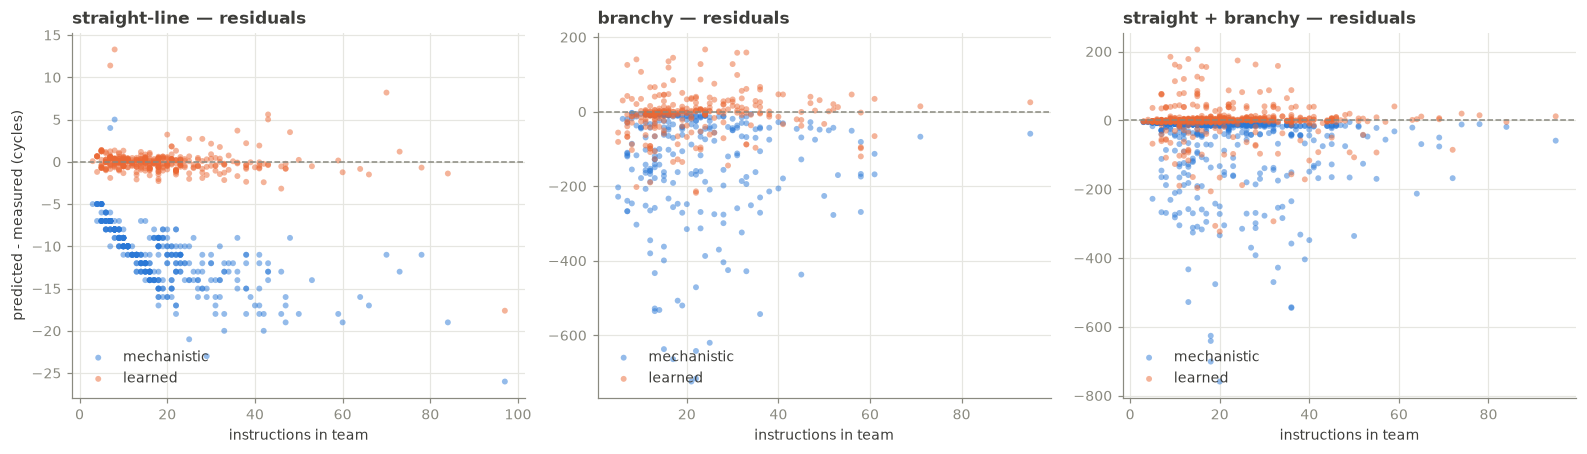

In [29]:
fig, axes = plt.subplots(1, len(FIT_SETS), figsize=(14.5, 4.2))
for k, (ax, name) in enumerate(zip(axes, FIT_SETS)):
    _tr, te = splits[name]
    n = np.array([rows[i].n for i in te], float)
    r = results[name]
    ax.axhline(0, color=MUTED, lw=1, ls="--")
    ax.scatter(n, r["mech"] - r["y"], s=15, color=C_MECH, alpha=0.5,
               edgecolor="none", label="mechanistic")
    ax.scatter(n, r["learn"] - r["y"], s=15, color=C_LEARN, alpha=0.5,
               edgecolor="none", label="learned")
    ax.set(xlabel="instructions in team",
           ylabel="predicted - measured (cycles)" if k == 0 else "",
           title=f"{name} — residuals")
    ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

## What to read off the output

This notebook is built to be re-run as features and costs change, so the
conclusions are stated as things to check rather than fixed numbers.

- **Straight-line.** Expect the mechanistic model to be a biased-but-tight floor and
  the learned model to remove that bias. The gap between them should be close to the
  constant + ~11% scale factor quantified in notebook 1 — which is exactly what a
  fitted intercept and slope absorb. Little mystery here.
- **Branchy.** Expect the learned model to win by a wide margin — and read section 5
  before calling that success. It is fitting a *static* feature vector to a *dynamic*
  measurement, so what it learned is a property of this workload's branch behaviour,
  not of the microarchitecture. Transfer performance is the tell.
- **Weights vs manual (section 4).** If the learned operation weights cluster on the
  diagonal, the regression is re-deriving the manual and the mechanistic model is
  validated. If they sit systematically above it, they are absorbing the per-team
  constant and the stall budget — the regression would then be right for reasons the
  manual does not contain.

**The thing to fix remains dynamic instruction counts.** Neither model can be right
on branchy teams while the features count instructions that never execute; the
learned model only hides that in fitted coefficients.